# 60. 상가정보 결합: 업소당 손실과 동 단위 취약 지도

입력: `08_stores.py`(소상공인시장진흥공단 상가정보 2026.06, 강남구·춘천시 업소 84,253개 → 카드 업종 매핑, UTM-K 좌표, SK 격자·행정동 결합)와 30·40번의 민감도·손실 표.

1. 업종별 업소 수 → 업소당 매출·손실(지원 단가 설계의 단위), 취약 등급 업종의 업소 수
2. 행정동 단위: 취약 업종 업소 수, 호우 하루 예상 손실(지역×업종 손실을 업소 수 비례로 배분), 유동인구 구조(SK) → 지원 우선 동
3. 폭염 건강 노출: 60대 이상 유동인구가 몰리는 곳(무더위쉼터·폭염 대응 위치 근거)

가정과 주의
- 같은 지역·업종이면 동이 달라도 업소당 민감도·매출이 같다고 본다(카드 데이터가 시군구 단위라 동별 민감도는 측정할 수 없다).
- 상가정보는 2026년 6월 기준이고 카드 데이터는 2025년 하반기다. 업소 수는 천천히 바뀌므로 비율 지표로 쓰되 기준 시점 차이를 적어 둔다.
- 상가 DB의 업소 수는 신한카드 가맹점 수가 아니라 영업 중으로 등록된 전체 업소 수다. 폐업 반영이 늦을 수 있다.

출력: `outputs/tables/st_*.csv`, 그림 `st*.png`

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, Normalize

sys.path.insert(0, str(Path.cwd()))
from common import (FIG, TAB, REGIONS, REGION_NAME, FACE_GROUPS, load, industry_map)
from analysis import (RC, SURFACE, INK, INK2, MUTED, GRID, AXIS, WASH, REGION_COLOR, finish)

FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(RC)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 60); pd.set_option("display.max_rows", 200)

st = load("stores_clean"); ind = load("stores_industry"); semd = load("stores_emd")
cells = load("sk_cell"); cell_emd = load("sk_cell_emd"); emd_pop = load("sk_emd_pop")
prof = load("industry_profile")
v = pd.read_csv(TAB / "v_index.csv", encoding="utf-8-sig")
perday = pd.read_csv(TAB / "v_perday.csv", encoding="utf-8-sig")
im = industry_map()[["industry", "group"]]
ASOF = st["asof"].iloc[0]
print(f"업소 {len(st):,}개(기준 {ASOF[:4]}.{ASOF[4:]}), 매핑된 업종 {ind.industry.nunique()}개, 행정동 {st.emd_name.nunique()}개")

업소 84,253개(기준 2026.06), 매핑된 업종 63개, 행정동 47개


## 1. 업종별 업소 수와 업소당 지표

범위는 소상공인 중심 대면 업종(팀 결정). 골프장·놀이동산·대형마트·쇼핑몰 같은 대형 업종은 뺀다.

In [2]:
keys = ["region", "industry"]
face_v = v[(v.face == 1) & (v.small_biz == 1)][keys + ["group", "sales_total", "sales_day", "loss_total", "loss_rate", "loss_per_day_rain_biz10", "loss_per_day_tropical", "loss_per_day_heat_day", "S_rain_biz10", "V", "grade_V"]]  # 소상공인 중심 대면 업종만
t = face_v.merge(ind, on=keys, how="left")
t["sales_day_per_store_만원"] = t.sales_day / t.n_stores / 1e4
t["loss6_per_store_만원"] = t.loss_total / t.n_stores / 1e4
t["rain_loss_day_per_store_만원"] = t.loss_per_day_rain_biz10.fillna(0) / t.n_stores / 1e4
t["vuln"] = t.grade_V.isin(["취약", "매우 취약"]).astype(int)
cov = t.groupby("region").apply(lambda g: pd.Series({"소상공인 시리즈": len(g), "업소 수 있는 시리즈": g.n_stores.notna().sum(),
                                                    "매출 커버리지(%)": g.loc[g.n_stores.notna(), "sales_total"].sum() / g.sales_total.sum() * 100,
                                                    "업소 합계": g.n_stores.sum(), "취약 등급 업소": g.loc[g.vuln == 1, "n_stores"].sum()}), include_groups=False)
t.round(3).to_csv(TAB / "st_industry.csv", index=False, encoding="utf-8-sig")
print(cov.round(1))
t[t.n_stores.notna()].sort_values("rain_loss_day_per_store_만원", ascending=False)[keys + ["group", "n_stores", "sales_day_per_store_만원", "rain_loss_day_per_store_만원", "loss6_per_store_만원", "grade_V"]].head(20).round(1)

           소상공인 시리즈  업소 수 있는 시리즈  매출 커버리지(%)    업소 합계  취약 등급 업소
region                                                         
chuncheon      40.0         38.0        98.9  11912.0    3061.0
gangnam        42.0         40.0        99.4  26282.0    1604.0


,region,industry,group,n_stores,sales_day_per_store_만원,rain_loss_day_per_store_만원,loss6_per_store_만원,grade_V
53,gangnam,서점,생활·기타소매,109.0,370.4,31.1,528.5,보통
16,chuncheon,스포츠/레저용품,생활·기타소매,104.0,166.7,16.8,353.0,보통
56,gangnam,스포츠/레저용품,생활·기타소매,281.0,243.8,14.0,238.6,보통
67,gangnam,인테리어/건축자재/주방기구,생활·기타소매,146.0,114.3,13.2,224.3,취약
0,chuncheon,가구,생활·기타소매,55.0,36.6,12.3,259.1,매우 취약
43,gangnam,기타요식,음식점,2112.0,103.9,11.7,198.1,보통
69,gangnam,정육점,식품·생필품,105.0,132.1,11.6,197.8,보통
27,chuncheon,일식,음식점,134.0,61.8,11.3,237.7,취약
6,chuncheon,농수산물,식품·생필품,121.0,60.8,9.0,188.5,취약
18,chuncheon,시계/귀금속,패션·잡화,43.0,52.3,8.6,216.3,취약


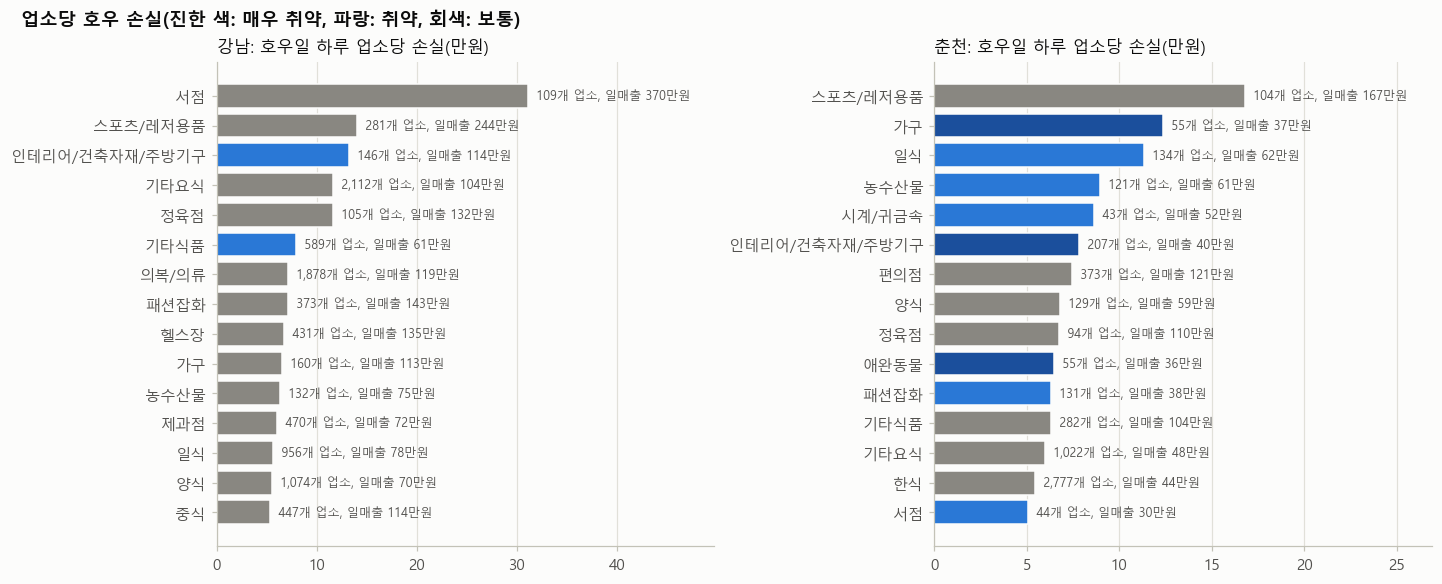

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), layout="constrained")
for ax, r in zip(axes, REGIONS):
    x = t[(t.region == r) & t.n_stores.notna() & (t.rain_loss_day_per_store_만원 > 0)].sort_values("rain_loss_day_per_store_만원", ascending=False).head(15)
    colors = ["#1b4f9c" if g == "매우 취약" else ("#2a78d6" if g == "취약" else "#898781") for g in x.grade_V]
    ax.barh(range(len(x)), x.rain_loss_day_per_store_만원, color=colors, edgecolor=SURFACE)
    for i, (n, s) in enumerate(zip(x.n_stores, x.sales_day_per_store_만원)):
        ax.text(x.rain_loss_day_per_store_만원.iloc[i], i, f"  {int(n):,}개 업소, 일매출 {s:.0f}만원", va="center", fontsize=8, color=INK2)
    ax.set_yticks(range(len(x)), x.industry); ax.invert_yaxis(); ax.set_title(f"{REGION_NAME[r]}: 호우일 하루 업소당 손실(만원)"); ax.grid(axis="y", visible=False)
    ax.set_xlim(0, x.rain_loss_day_per_store_만원.max() * 1.6)
finish(fig, FIG, "st01_loss_per_store", "업소당 호우 손실(진한 색: 매우 취약, 파랑: 취약, 회색: 보통)")
plt.show()

### 소상공인 플래그 점검: 업소당 매출로 본 대형 업종 혼재
카드 데이터에는 가맹점 규모가 없어 소상공인 여부는 업종 단위 판단(industry_map.small_biz)이다. 상가정보 업소 수로 업소당 하루 매출을 구해 판단과 어긋나는 업종을 표시한다(플래그 1인데 업소당 200만 원 이상이면 '대형 혼재 의심', 플래그 0인데 100만 원 이하면 '소상공인 가능'). 플래그 변경은 팀 결정.

In [4]:
chk = v[v.face == 1][keys + ["group", "small_biz", "sales_day", "grade_V"]].merge(ind, on=keys, how="left")
chk["업소당 일매출(만원)"] = chk.sales_day / chk.n_stores / 1e4
chk["점검"] = np.select([(chk.small_biz == 1) & (chk["업소당 일매출(만원)"] >= 200), (chk.small_biz == 0) & (chk["업소당 일매출(만원)"] <= 100)], ["대형 혼재 의심", "소상공인 가능"], "")
chk["지역"] = chk.region.map(REGION_NAME)
chk = chk.sort_values(["small_biz", "업소당 일매출(만원)"], ascending=[True, False])
chk[["지역", "industry", "group", "small_biz", "n_stores", "업소당 일매출(만원)", "grade_V", "점검"]].round(0).to_csv(TAB / "st_small_biz_check.csv", index=False, encoding="utf-8-sig")
med = chk.dropna(subset=["n_stores"]).groupby("small_biz")["업소당 일매출(만원)"].median().round(0)
print(f"업소당 일매출 중앙값: 플래그 0(대형) {med.get(0, float('nan')):.0f}만원, 플래그 1(소상공인) {med.get(1, float('nan')):.0f}만원")
chk[chk.점검 != ""][["지역", "industry", "group", "small_biz", "n_stores", "업소당 일매출(만원)", "점검"]].round(0)

업소당 일매출 중앙값: 플래그 0(대형) 294만원, 플래그 1(소상공인) 46만원


,지역,industry,group,small_biz,n_stores,업소당 일매출(만원),점검
1,춘천,가전,생활·기타소매,0,64.0,97.0,소상공인 가능
35,춘천,종합레저타운/놀이동산,여가·스포츠,0,63.0,79.0,소상공인 가능
32,춘천,장례식장/묘지/장의사,개인서비스,0,39.0,42.0,소상공인 가능
71,강남,실내/실외골프장,여가·스포츠,0,214.0,19.0,소상공인 가능
64,강남,서점,생활·기타소매,1,109.0,370.0,대형 혼재 의심
68,강남,스포츠/레저용품,생활·기타소매,1,281.0,244.0,대형 혼재 의심
73,강남,악기/음반,생활·기타소매,1,13.0,202.0,대형 혼재 의심


## 2. 행정동 단위: 취약 업소, 예상 손실, 유동인구

동별 호우 하루 예상 손실 = Σ_업종 (동의 업소 수 / 지역 업소 수) × 지역×업종 호우 하루 손실. 취약 업소 = 취약·매우 취약 등급 업종의 업소.

In [5]:
alloc = semd.dropna(subset=["industry"]).merge(t[keys + ["n_stores", "loss_per_day_rain_biz10", "loss_total", "vuln", "sales_day"]].rename(columns={"n_stores": "n_region"}), on=keys, how="inner")
alloc["rain_loss_day"] = alloc.n_stores / alloc.n_region * alloc.loss_per_day_rain_biz10.fillna(0)
alloc["loss6"] = alloc.n_stores / alloc.n_region * alloc.loss_total.fillna(0)
alloc["sales_day_alloc"] = alloc.n_stores / alloc.n_region * alloc.sales_day.fillna(0)
alloc["n_vuln"] = alloc.n_stores * alloc.vuln
E = alloc.groupby(["region", "emd_name"]).agg(n_face=("n_stores", "sum"), n_vuln=("n_vuln", "sum"), rain_loss_day=("rain_loss_day", "sum"),
                                              loss6=("loss6", "sum"), sales_day=("sales_day_alloc", "sum")).reset_index()
E["vuln_share"] = E.n_vuln / E.n_face
cent = st.groupby(["region", "emd_name"])[["x", "y"]].mean().reset_index().rename(columns={"x": "cx", "y": "cy"})
E = E.merge(cent, on=["region", "emd_name"], how="left").merge(emd_pop[["region", "emd_name", "pop", "pop60", "share_age_60p", "share_tb_12_17", "n_cells"]], on=["region", "emd_name"], how="left")
E["rain_loss_day_억"] = E.rain_loss_day / 1e8
E["loss6_억"] = E.loss6 / 1e8
E["rank_loss"] = E.groupby("region").rain_loss_day.rank(ascending=False).astype(int)
E["rank_vuln"] = E.groupby("region").n_vuln.rank(ascending=False).astype(int)
E = E.sort_values(["region", "rain_loss_day"], ascending=[True, False])
E.round(4).to_csv(TAB / "st_emd.csv", index=False, encoding="utf-8-sig")
show = E[["region", "emd_name", "n_face", "n_vuln", "vuln_share", "rain_loss_day_억", "loss6_억", "pop", "share_age_60p"]].copy()
show["pop"] = (show["pop"] / 1e4).round(1)
print("동별 상위 8 (호우 하루 예상 손실 기준, pop 단위 만명)")
show.groupby("region").head(8).round(3)

동별 상위 8 (호우 하루 예상 손실 기준, pop 단위 만명)


,region,emd_name,n_face,n_vuln,vuln_share,rain_loss_day_억,loss6_억,pop,share_age_60p
18,chuncheon,퇴계동,1516,310,0.204,0.563,11.885,29.0,0.223
11,chuncheon,석사동,1295,317,0.245,0.509,10.748,19.2,0.216
0,chuncheon,강남동,950,271,0.285,0.357,7.509,22.1,0.248
5,chuncheon,동내면,699,178,0.255,0.278,5.839,6.9,0.245
17,chuncheon,조운동,578,211,0.365,0.235,5.146,5.7,0.260
6,chuncheon,동면,562,154,0.274,0.231,4.865,6.9,0.240
15,chuncheon,신사우동,579,125,0.216,0.229,4.807,12.8,0.262
22,chuncheon,후평1동,522,113,0.216,0.216,4.602,8.8,0.239
42,gangnam,역삼1동,4961,258,0.052,2.165,37.008,122.6,0.142
41,gangnam,압구정동,2311,92,0.040,1.164,19.913,42.7,0.191


### 대안: 동별 배분 가중치를 업소 수 대신 추정매출로
서울시 상권분석서비스 추정매출(행정동×업종, 2025년 3·4분기, 신한카드 기반)을 `meta/seoul_ind_map.csv`로 카드 업종에 매핑해 강남구 동별 배분 가중치로 쓴다. 매핑이 없는 업종과 춘천(자료 없음)은 업소 수 비례를 유지한다. 기본 지도와 표는 업소 수 비례(팀 결정)이고, 여기서는 두 방식의 차이를 본다.

In [6]:
smap = pd.read_csv(Path.cwd() / "meta" / "seoul_ind_map.csv", encoding="utf-8-sig").dropna(subset=["seoul_names"])
smap = smap.assign(seoul_nm=smap.seoul_names.str.split("|")).explode("seoul_nm")[["industry", "seoul_nm"]]
se = load("seoul_sales_emd")
se = se[(se.year == 2025) & se.q.isin([3, 4])].merge(smap, left_on="ind_nm", right_on="seoul_nm", how="inner")
se["area_nm"] = se.area_nm.replace({"일원2동": "개포3동"})  # 2023년 행정동 개편(일원2동 → 개포3동) 반영. 상가정보는 새 이름을 쓴다
w = se.groupby(["area_nm", "industry"]).amt.sum().reset_index().rename(columns={"area_nm": "emd_name"})
w["region"] = "gangnam"
w["w_sales"] = w.amt / w.groupby(keys).amt.transform("sum")
base = t[keys + ["loss_per_day_rain_biz10", "loss_total", "vuln", "sales_day"]]
ws = w.merge(base, on=keys, how="inner")  # 매출 가중(강남, 매핑된 업종)
mapped = set(zip(ws.region, ws.industry))
unmatched = sorted(set(w.emd_name) - set(semd.loc[semd.region == "gangnam", "emd_name"]))
print("추정매출 행정동 이름 중 상가정보와 다른 것:", unmatched or "없음")
ws["rain_loss_day"] = ws.w_sales * ws.loss_per_day_rain_biz10.fillna(0)
ws["loss6"] = ws.w_sales * ws.loss_total.fillna(0)
wst = alloc[[not ((r, i) in mapped) for r, i in zip(alloc.region, alloc.industry)]]  # 나머지는 업소 수 비례
E2 = pd.concat([ws[["region", "emd_name", "rain_loss_day", "loss6"]], wst[["region", "emd_name", "rain_loss_day", "loss6"]]]).groupby(["region", "emd_name"]).sum().reset_index()
E2 = E2.rename(columns={"rain_loss_day": "rain_loss_day_sales", "loss6": "loss6_sales"})
cov_g = ws.groupby("region").loss_per_day_rain_biz10.apply(lambda s: s.fillna(0).groupby(level=0).first().sum())
tot_g = base[base.region == "gangnam"].loss_per_day_rain_biz10.fillna(0).sum()
mapped_loss = base[[((r, i) in mapped) for r, i in zip(base.region, base.industry)]].loss_per_day_rain_biz10.fillna(0).sum()
print(f"강남 소상공인 호우 하루 손실 중 매출 가중치로 배분한 비중: {mapped_loss / tot_g * 100:.1f}% (매핑 업종 {len(mapped)}개)")
E = E.merge(E2, on=["region", "emd_name"], how="left")
E["rain_loss_day_sales_억"] = E.rain_loss_day_sales / 1e8
E["rank_loss_sales"] = E.groupby("region").rain_loss_day_sales.rank(ascending=False).astype("Int64")
E.round(4).to_csv(TAB / "st_emd.csv", index=False, encoding="utf-8-sig")
g = E[E.region == "gangnam"].sort_values("rain_loss_day", ascending=False)
from scipy.stats import spearmanr
rho = spearmanr(g.rain_loss_day, g.rain_loss_day_sales).correlation
cmp = g[["emd_name", "n_face", "rain_loss_day_억", "rank_loss", "rain_loss_day_sales_억", "rank_loss_sales"]].copy()
cmp["차이(%)"] = ((cmp.rain_loss_day_sales_억 / cmp.rain_loss_day_억 - 1) * 100).round(0)
cmp.round(3).to_csv(TAB / "st_emd_weight_compare.csv", index=False, encoding="utf-8-sig")
top3_store = g.rain_loss_day.head(3).sum() / g.rain_loss_day.sum() * 100
gs = g.sort_values("rain_loss_day_sales", ascending=False)
top3_sales = gs.rain_loss_day_sales.head(3).sum() / gs.rain_loss_day_sales.sum() * 100
print(f"강남 동 순위 상관(업소 수 vs 매출 비례) {rho:.2f}; 상위 3개 동 비중 {top3_store:.0f}% → {top3_sales:.0f}%; 매출 비례 상위 5: {', '.join(gs.emd_name.head(5))}")
cmp.head(12).round(2)

추정매출 행정동 이름 중 상가정보와 다른 것: 없음
강남 소상공인 호우 하루 손실 중 매출 가중치로 배분한 비중: 98.5% (매핑 업종 33개)
강남 동 순위 상관(업소 수 vs 매출 비례) 0.94; 상위 3개 동 비중 36% → 38%; 매출 비례 상위 5: 역삼1동, 압구정동, 청담동, 삼성1동, 논현2동


,emd_name,n_face,rain_loss_day_억,rank_loss,rain_loss_day_sales_억,rank_loss_sales,차이(%)
25,역삼1동,4961,2.16,1,2.03,1,-6.0
26,압구정동,2311,1.16,2,1.29,2,11.0
27,청담동,2270,0.98,3,1.25,3,27.0
28,신사동,2087,0.95,4,0.88,6,-7.0
29,논현2동,2152,0.95,5,1.04,5,9.0
30,논현1동,2053,0.89,6,0.76,7,-14.0
31,삼성1동,1494,0.75,7,1.20,4,61.0
32,대치4동,1535,0.73,8,0.71,8,-3.0
33,역삼2동,1226,0.52,9,0.43,9,-19.0
34,삼성2동,1220,0.51,10,0.34,11,-34.0


지도: 동 중심(업소 좌표 평균)에 원을 그린다. 원 크기 = 호우 하루 예상 손실, 색 = 취약 업소 비율. 배경은 SK 유동인구(옅을수록 적음).

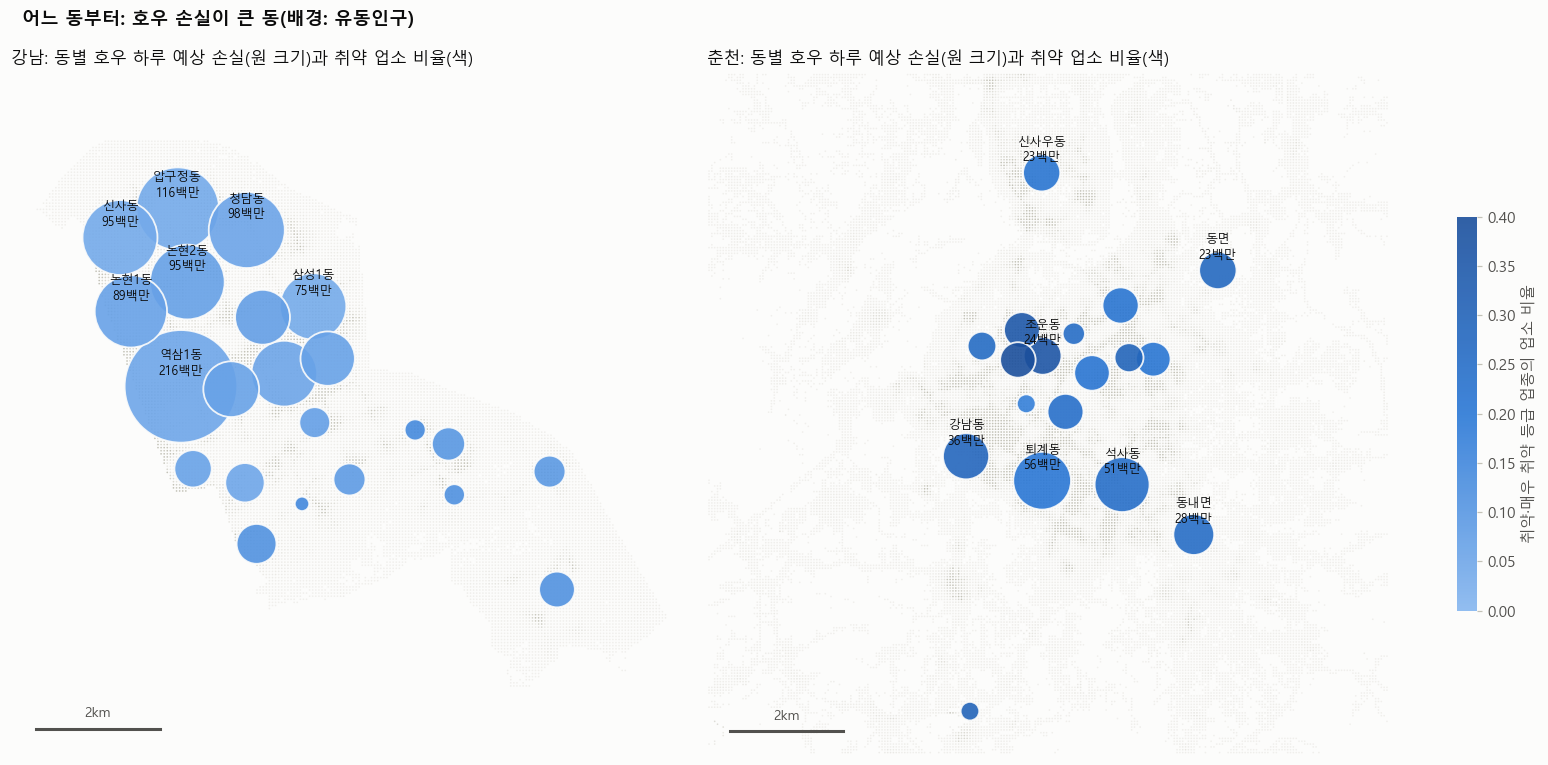

In [7]:
HALF = {"gangnam": 5500, "chuncheon": 6000}
def base_map(ax, r, color_col="pop", cmap=None, vmax=None):
    c = cells[(cells.region == r) & (cells["pop"] > 0)]
    if r == "gangnam":
        cx, cy = (c.x.min() + c.x.max()) / 2, (c.y.min() + c.y.max()) / 2
    else:
        cx, cy = np.average(c.x, weights=c["pop"]), np.average(c.y, weights=c["pop"])
    h = HALF[r]
    c = c[(c.x.between(cx - h, cx + h)) & (c.y.between(cy - h, cy + h))]
    val = c[color_col] if color_col in c else c["pop"]
    ax.scatter(c.x, c.y, s=1.2, c=val, cmap=cmap or LinearSegmentedColormap.from_list("bg", [WASH, "#c3c2b7"]), norm=Normalize(0, vmax or val.quantile(0.95)), linewidths=0, rasterized=True)
    ax.set_xlim(cx - h, cx + h); ax.set_ylim(cy - h, cy + h); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.plot([cx - h + 400, cx - h + 2400], [cy - h + 400] * 2, color=INK2, lw=2); ax.text(cx - h + 1400, cy - h + 600, "2km", ha="center", fontsize=9, color=INK2)
    return cx, cy, h

cmap_v = LinearSegmentedColormap.from_list("v", ["#86b6ef", "#2a78d6", "#1b4f9c"])
fig, axes = plt.subplots(1, 2, figsize=(14, 7), layout="constrained")
for ax, r in zip(axes, REGIONS):
    cx, cy, h = base_map(ax, r)
    e = E[(E.region == r) & E.cx.between(cx - h, cx + h) & E.cy.between(cy - h, cy + h)]
    sc = ax.scatter(e.cx, e.cy, s=e.rain_loss_day / 1e6 * 25 + 20, c=e.vuln_share, cmap=cmap_v, norm=Normalize(0, 0.4), edgecolors=SURFACE, linewidths=1.2, alpha=0.9, zorder=5)
    for _, row in e.sort_values("rain_loss_day", ascending=False).head(7).iterrows():
        ax.annotate(f"{row.emd_name}\n{row.rain_loss_day/1e6:.0f}백만", (row.cx, row.cy), fontsize=8, color=INK, ha="center", va="bottom", xytext=(0, 6), textcoords="offset points", zorder=6)
    ax.set_title(f"{REGION_NAME[r]}: 동별 호우 하루 예상 손실(원 크기)과 취약 업소 비율(색)")
cb = fig.colorbar(sc, ax=axes, shrink=0.55, label="취약·매우 취약 등급 업종의 업소 비율"); cb.outline.set_visible(False)
finish(fig, FIG, "st02_map_rain", "어느 동부터: 호우 손실이 큰 동(배경: 유동인구)")
plt.show()

## 3. 폭염 건강 노출: 60대 이상 유동인구가 몰리는 곳

폭염은 매출 손실이 확인되지 않았지만 고령 보행자의 건강 위험은 공간적으로 집중된다. 셀별 60대+ 유동인구(인구 × 60대+ 비중)를 그리고 상위 동을 표시한다. 무더위쉼터·그늘막·급수대 같은 대응의 위치 근거로 쓴다.

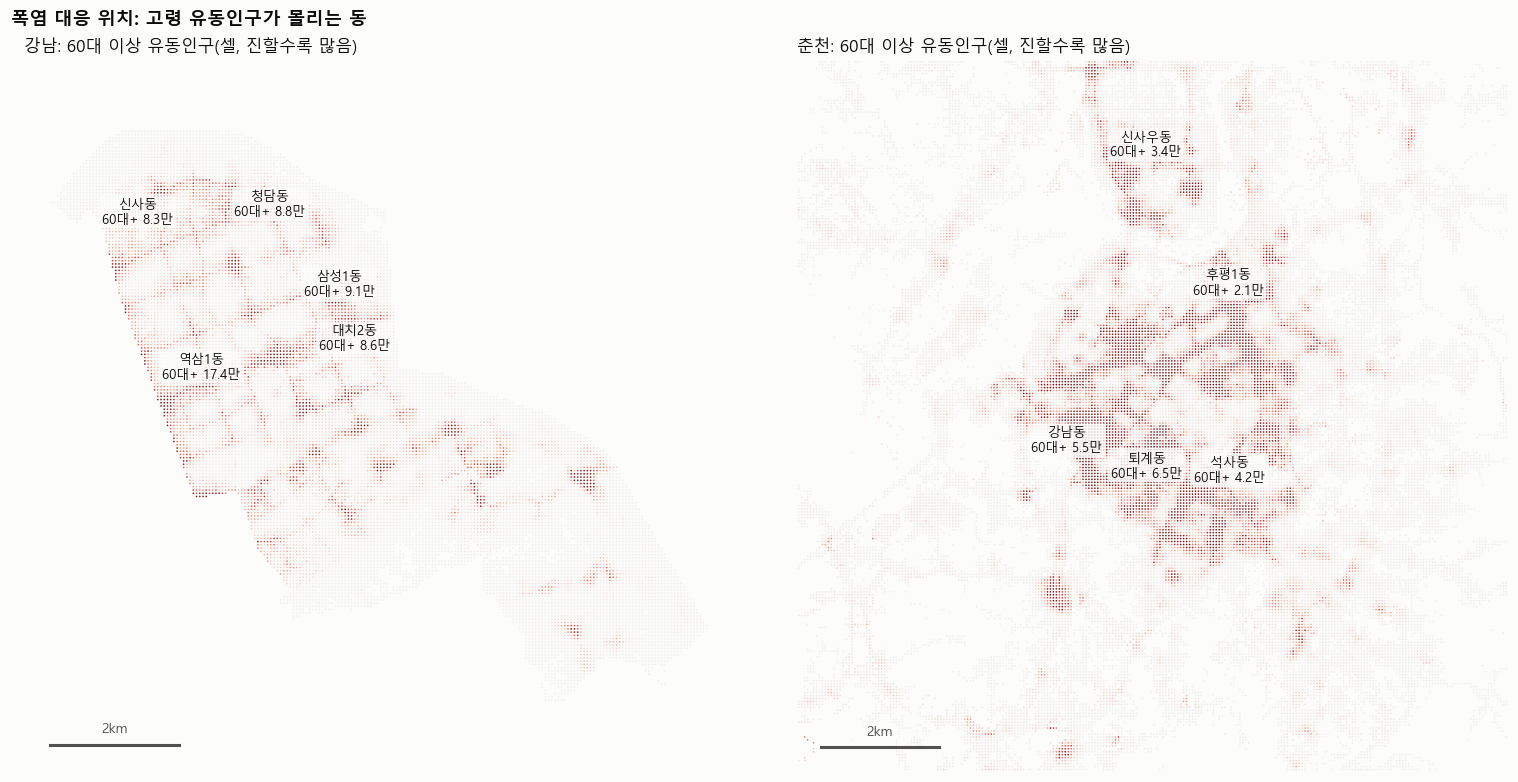

,region,emd_name,pop60,share_age_60p,n_face,n_vuln
25,gangnam,역삼1동,17.4,0.142,4961,258
31,gangnam,삼성1동,9.1,0.152,1494,55
27,gangnam,청담동,8.8,0.196,2270,129
35,gangnam,대치2동,8.6,0.174,1055,69
28,gangnam,신사동,8.3,0.193,2087,84
0,chuncheon,퇴계동,6.5,0.223,1516,310
2,chuncheon,강남동,5.5,0.248,950,271
1,chuncheon,석사동,4.2,0.216,1295,317
6,chuncheon,신사우동,3.4,0.262,579,125
7,chuncheon,후평1동,2.1,0.239,522,113


In [8]:
cells["pop60"] = cells["pop"] * cells.share_age_60p.fillna(0)
cmap_h = LinearSegmentedColormap.from_list("h", [WASH, "#f0a08a", "#e34948", "#7a1f1f"])
fig, axes = plt.subplots(1, 2, figsize=(14, 7), layout="constrained")
for ax, r in zip(axes, REGIONS):
    cx, cy, h = base_map(ax, r, color_col="pop60", cmap=cmap_h, vmax=cells.loc[(cells.region == r), "pop60"].quantile(0.98))
    e = E[(E.region == r) & E.cx.between(cx - h, cx + h) & E.cy.between(cy - h, cy + h)].sort_values("pop60", ascending=False).head(5)
    for _, row in e.iterrows():
        ax.annotate(f"{row.emd_name}\n60대+ {row.pop60/1e4:.1f}만", (row.cx, row.cy), fontsize=8.5, color=INK, ha="center", va="bottom", xytext=(0, 4), textcoords="offset points",
                    bbox=dict(boxstyle="round,pad=0.2", fc=SURFACE, ec="none", alpha=0.8))
    ax.set_title(f"{REGION_NAME[r]}: 60대 이상 유동인구(셀, 진할수록 많음)")
finish(fig, FIG, "st03_map_elderly", "폭염 대응 위치: 고령 유동인구가 몰리는 동")
plt.show()
E.sort_values("pop60", ascending=False).groupby("region").head(5)[["region", "emd_name", "pop60", "share_age_60p", "n_face", "n_vuln"]].assign(pop60=lambda x: (x.pop60 / 1e4).round(1)).round(3)

## 4. 시나리오와 연결: 업소당 예상 손실

40번의 시나리오 1(춘천 토요일 30mm 호우) 우선순위 표에 업소 수를 붙여 업소당 예상 손실을 본다. 지원 단가(업소당)와 총액(동별·업종별)을 같이 설계할 수 있다.

In [9]:
S1 = pd.read_csv(TAB / "m_priority_S1_chuncheon_rain.csv", encoding="utf-8-sig").merge(ind, on=["region", "industry"], how="left")
S1["loss_per_store_만원"] = S1.expected_loss / S1.n_stores / 1e4
S1.round(3).to_csv(TAB / "st_priority_S1_per_store.csv", index=False, encoding="utf-8-sig")
S1[S1.small_biz == 1].head(12)[["industry", "group", "p_alert", "expected_loss", "n_stores", "loss_per_store_만원", "grade_V"]].assign(expected_loss=lambda x: (x.expected_loss / 1e6).round(0)).rename(columns={"expected_loss": "예상 손실(백만원)"}).round(2)

,industry,group,p_alert,예상 손실(백만원),n_stores,loss_per_store_만원,grade_V
2,기타요식,음식점,0.64,79.0,1022.0,7.72,보통
3,한식,음식점,0.21,202.0,2777.0,7.28,보통
5,일식,음식점,0.80,23.0,134.0,17.13,취약
6,스포츠/레저용품,생활·기타소매,0.48,30.0,104.0,29.28,보통
7,커피전문점,카페·베이커리,0.78,16.0,827.0,1.95,취약
8,기타식품,식품·생필품,0.52,22.0,282.0,7.93,보통
9,생활잡화/수입상품점,생활·기타소매,0.70,16.0,291.0,5.63,취약
11,의복/의류,패션·잡화,0.51,21.0,641.0,3.28,취약
12,인테리어/건축자재/주방기구,생활·기타소매,0.63,13.0,207.0,6.50,매우 취약
13,미용실,개인서비스,0.35,21.0,903.0,2.30,보통


## 요약

- `st_industry.csv`: 지역×업종 업소 수, 업소당 매출·손실, 등급. `st_emd.csv`: 행정동별 취약 업소·예상 손실·유동인구. `st_priority_S1_per_store.csv`: 시나리오 업소당 손실.
- 그림 `st01`(업소당 손실), `st02`(동별 호우 손실 지도), `st03`(고령 유동인구 지도).

In [10]:
summary = {}
for r in REGIONS:
    e = E[E.region == r].sort_values("rain_loss_day", ascending=False)
    summary[REGION_NAME[r]] = {"소상공인 업소(매핑)": int(t[(t.region == r)].n_stores.sum()), "취약 등급 업소": int(t[(t.region == r) & (t.vuln == 1)].n_stores.sum()),
                               "호우 하루 손실 상위 3개 동": ", ".join(e.emd_name.head(3)), "상위 3개 동 손실 비중(%)": round(e.rain_loss_day.head(3).sum() / e.rain_loss_day.sum() * 100, 1),
                               "60대+ 유동인구 상위 동": E[E.region == r].sort_values("pop60", ascending=False).emd_name.iloc[0]}
pd.DataFrame(summary).to_csv(TAB / "st_summary.csv", encoding="utf-8-sig")
pd.DataFrame(summary)

,강남,춘천
소상공인 업소(매핑),26282,11912
취약 등급 업소,1604,3061
호우 하루 손실 상위 3개 동,"역삼1동, 압구정동, 청담동","퇴계동, 석사동, 강남동"
상위 3개 동 손실 비중(%),36.2,31.9
60대+ 유동인구 상위 동,역삼1동,퇴계동
